In [3]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print ("Libraries imported successfully")

Libraries imported successfully


In [4]:
import sys

print("sys.executable:", sys.executable)

sys.executable: /Users/alexispgeorge/Documents/YEAR 4 LESSONS/Natural Language Processing/Practical/ReviewSense-AI/.venv/bin/python


In [5]:
df = pd.read_json("../dataset/reviews.json")
print("Dataset loaded successfully")
print(df.shape)
df.head(10)

Dataset loaded successfully
(4500, 4)


,id,review,stars,sentiment
0,3555,I decided initially on Fiesta due to their loc...,4,positive
1,1169,I've been in a Menards a LOT ever since I was ...,2,negative
2,636,"In General, I consider the Olive Garden chain ...",1,negative
3,858,After 5 years in Phoenix and so much anticipat...,2,negative
4,3710,"I enjoyed myself here, but wasn't really impre...",4,positive
5,4380,Good beer specials when I've had their beer sp...,5,positive
6,1880,I normally won't eat at the ichi Ban chain. Th...,3,neutral
7,3975,"La Feria recently changed their menu, so I tho...",5,positive
8,3693,I keep wanting to call this place Anne of Gree...,4,positive
9,2428,Confusing! No one to greet me so I wasn't sure...,3,neutral


In [6]:
df.describe(include='all')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         4500 non-null   int64
 1   review     4500 non-null   str  
 2   stars      4500 non-null   int64
 3   sentiment  4500 non-null   str  
dtypes: int64(2), str(2)
memory usage: 3.2 MB


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate review texts:",
    df["review"].duplicated().sum()
)

Duplicate rows: 0
Duplicate review texts: 0


In [9]:
df.isnull().sum()

id           0
review       0
stars        0
sentiment    0
dtype: int64

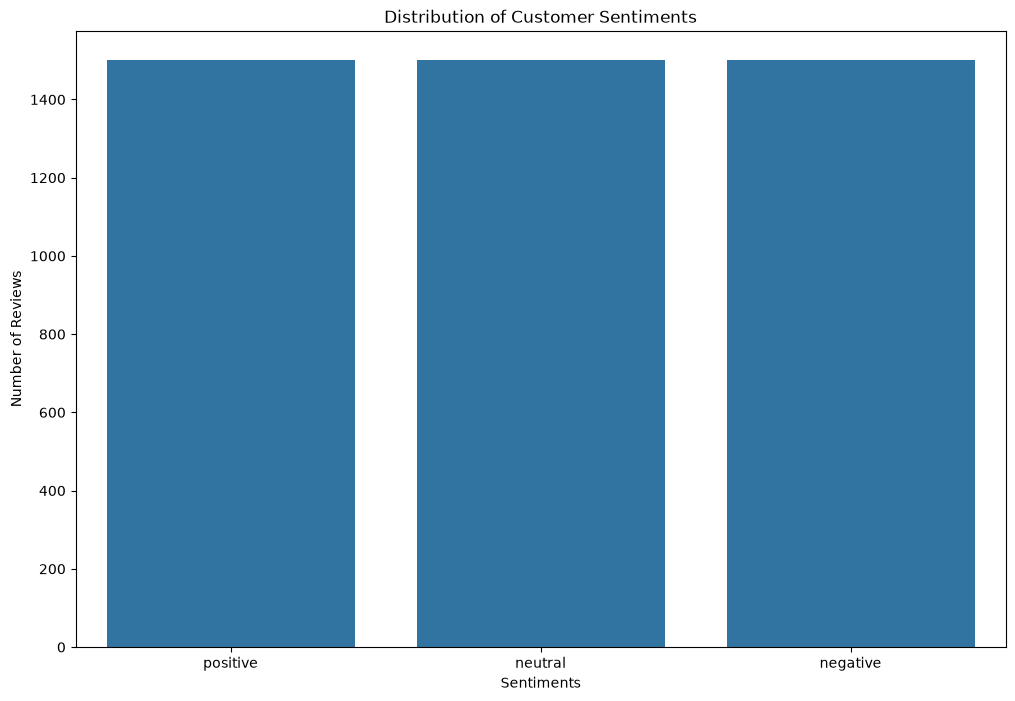

In [10]:
plt.figure(figsize=(12, 8))

sns.countplot(
    data=df,
    x="sentiment",
    order=["positive", "neutral", "negative"]
)
plt.title("Distribution of Customer Sentiments")
plt.xlabel("Sentiments")
plt.ylabel("Number of Reviews")
plt.show()

In [11]:
# Calculate the number of words in each review
df["word_count"] = df["review"].apply(
    lambda text: len(str(text).split())
)
# Display basic statistics
print(df["word_count"].describe())

count    4500.000000
mean      128.704000
std       115.521572
min         1.000000
25%        51.000000
50%        97.000000
75%       168.250000
max       954.000000
Name: word_count, dtype: float64


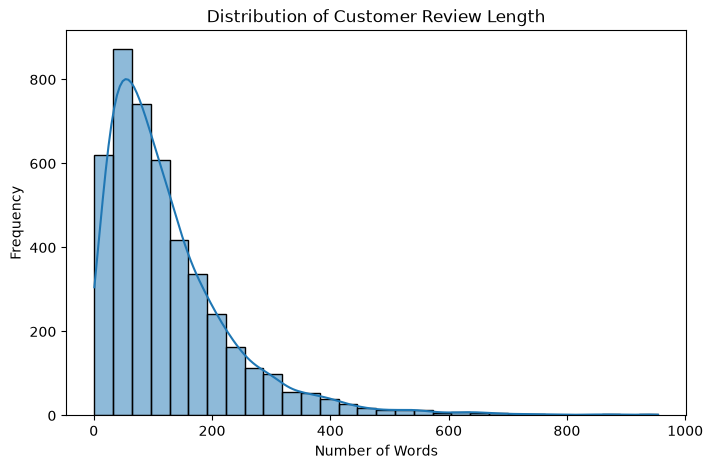

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [13]:
df[["review", "stars", "sentiment"]].sample(
    10,
    random_state=42
)

,review,stars,sentiment
2323,Grade: C\n\nAverage food. Average prices. Aver...,3,neutral
3686,Well this visit started off good. I was seated...,3,neutral
2974,I love love love this place! The tmb sandwich ...,5,positive
2992,Great window view and we received grade A cust...,3,neutral
468,I don't know why others had such a problem wit...,5,positive
2640,"The frozen cosmos and mimosas are great, espec...",4,positive
1909,ok food but most of it is frozen or canned and...,2,negative
151,Meh. I've experienced better. (default for 2 ...,2,negative
3895,I was visiting Charlotte for business and came...,3,neutral
3648,"Decent sushi, I prefer to sit up at the bar co...",2,negative


In [14]:
# Select one customer review
sample_review = df["review"].iloc[0]

print("Original review:")
print(sample_review)

# Convert review to lowercase
lowercase_review = sample_review.lower()

print("\nLowercase review:")
print(lowercase_review)

Original review:
I decided initially on Fiesta due to their location and ability to schedule appoint with a working mom. My LO had torticollis and needed some help. Our peditrician had referred him to a different office that blantely said they couldn't help me with my schedule.\nOnce decided it still took them a while to schedule an appointment, because all of a sudden there were no openings. Then there was a maybe and so with the scheduler \" Al' on the phone I took the day off, while at work. He would call me back. Nothing happened for 10 days, so I call them and yes there was one opening. Initially I need PT and OT. \n\nWe went in for OT and actually met the owner Beth, she was very nice and when I explained it took me  2 months to schedule, she apologized and was very firm about me being able to schedule. I wasn't the only working mom right. She even asked me who in scheduling took that time to not get me in sooner. She went to the front desk and came back with an appoinment on the

In [15]:
print("Original:", sample_review)
print("Processed:", lowercase_review)

Original: I decided initially on Fiesta due to their location and ability to schedule appoint with a working mom. My LO had torticollis and needed some help. Our peditrician had referred him to a different office that blantely said they couldn't help me with my schedule.\nOnce decided it still took them a while to schedule an appointment, because all of a sudden there were no openings. Then there was a maybe and so with the scheduler \" Al' on the phone I took the day off, while at work. He would call me back. Nothing happened for 10 days, so I call them and yes there was one opening. Initially I need PT and OT. \n\nWe went in for OT and actually met the owner Beth, she was very nice and when I explained it took me  2 months to schedule, she apologized and was very firm about me being able to schedule. I wasn't the only working mom right. She even asked me who in scheduling took that time to not get me in sooner. She went to the front desk and came back with an appoinment on the day th

In [16]:
import re

In [17]:
def remove_html_urls(text):

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    return text

In [18]:
sample_text = """
I LOVE this product!

Visit https://example.com for more information.

<p>The customer service was excellent.</p>
"""

cleaned_text = remove_html_urls(sample_text)

print("Original text:")
print(sample_text)

print("\nCleaned text:")
print(cleaned_text)

Original text:

I LOVE this product!

Visit https://example.com for more information.

<p>The customer service was excellent.</p>


Cleaned text:

I LOVE this product!

Visit  for more information.

The customer service was excellent.

